# Limit model: rates against the old code, and the NESS

Photons (T1): vertical interband rates of the q -> 0 light cone. Phonons (T2): intraband,
c_s -> 0, as the gam -> 0 Fokker-Planck operator (`line: fp`) or the finite gam kernel
(`line: lorentz`). Everything is in `limit_model.py` and `limit_solve.py`; the old
`ei_phonon.py` is imported only for the comparison in section 1.
Temperatures are given in units of the equilibrium Tc of the same model.

In [29]:
import sys
from pathlib import Path
from types import SimpleNamespace as NS
from typing import NamedTuple

import numpy as np
import yaml
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import limit_model as lm
import limit_solve as ls

from utils.cosmetics import apply_plt_style
from utils.logger import logger
from utils.plotting_utils import Plotter

apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)

cfg = yaml.safe_load(open(HERE / "config" / "limit.yaml"))
p = lm.Pars(**cfg["model"]["band"], **cfg["model"]["mf"])
pc, qc, cmp = cfg["photon"], cfg["phonon"], cfg["compare"]
gr = lm.grid(cfg["grid"]["ns"])
tc = lm.tc(gr, p)
d00, m00, _ = lm.thermal(gr, p, 1e-4 * tc)      # Delta_0 = d(T -> 0), the energy unit of the plots
t1, t2 = cfg["ness"]["t1"] * tc, cfg["ness"]["t2"] * tc
eta0 = 0.5 * p.h * p.n
print(f"Tc = {tc:.6f}, Delta_0 = {d00:.6f}, T1 = {t1:.4f}, T2 = {t2:.4f}")

set1_list = plt.get_cmap("Set1").colors
W = 3.47412


def style(ax, x=None):
    ax.grid(alpha=0.3)
    ax.tick_params(which="both", direction="in")
    if x is not None:
        ax.set_xlim(np.min(x), np.max(x))

Tc = 0.535235, Delta_0 = 1.000057, T1 = 0.3211, T2 = 0.1070


## 1. Rates: old code against the limit model

Mean field state for the comparison: equilibrium at T2. The old code is evaluated on an
nk x nk Cartesian grid; its pair rates are per pair, so a rate per state is the pair rate
times w = 1 / N (as in `cur_block`).

In [30]:
import jax
sys.path.insert(0, str((HERE / cmp["old_src"]).resolve()))
import ei_phonon as pb


class St(NamedTuple):
    e: np.ndarray
    u: np.ndarray
    v: np.ndarray


dc, mc, _ = lm.thermal(gr, p, t2)
nk = cmp["nk"]
k1 = -np.pi + 2 * np.pi * np.arange(nk) / nk
kk = np.stack(np.meshgrid(k1, k1, indexing="ij"), -1).reshape(-1, 2)
N = nk * nk
bk = lm.mf(p, np.cos(kk).sum(-1), dc, mc)
st = St(np.stack((bk.ea, bk.eb)), bk.u, bk.v)

common = dict(k=kk, gap=p.gap, ta=p.ta, tb=p.tb, v=p.v, n=p.n, uh=p.uh)
ph_old = pb.PhononBath(t=t1, cs=pc["c"], dip=pc["dip"], amp=pc["amp"], w0=pc["w0"], gam=pc["gam"],
                       nsub=cmp["nsub"], kind="photon", **common)
qn_old = pb.PhononBath(t=t2, cs=cmp["cs"], dip=0.0, amp=qc["amp"], w0=0.0, gam=qc["gam"], nsub=0,
                       kind="phonon", ta_prime=qc["ta_prime"], tb_prime=qc["tb_prime"], **common)

# Gamma - X - M - Gamma path as integer offsets from Gamma
h, i0 = nk // 2, nk // 2
off = [(j, 0) for j in range(h + 1)] + [(h, j) for j in range(1, h + 1)] + [(h - j, h - j) for j in range(1, h + 1)]
ip = np.array([((i0 + a) % nk) * nk + (i0 + b) % nk for a, b in off])
kp = 2 * np.pi / nk * np.array(off, float)
xp = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(kp, axis=0), axis=1))]
xt = [0.0, xp[h], xp[2 * h], xp[-1]]
xl = [r"$\Gamma$", r"$X$", r"$M$", r"$\Gamma$"]


def path_axes(ax):
    ax.set_xticks(xt, xl)
    for v in xt[1:3]:
        ax.axvline(v, color="0.75", lw=0.7)
    style(ax, xp)

### 1a. Photons: vertical rates along the path

- limit, k resolved: closed form with |sin k|^2 at k,
- limit, s model: the same with the contour average Phi / g (what the 1D model uses),
- old grid: the q = 0 cell of `source_rates` (cell averaged line, nsub from the config),
- old vertex, light cone: eq. 186 with `pb.g_mat`, integrated over the cone of k - q.

In [31]:
def old_vertical(bath, ik, nu, mu, t, nw, nph):
    """Rate per state from (mu, k - q) to (nu, k) with the old vertex, q over the light cone
    up to omega = w0 + 20 (the far Lorentzian tail, up to omega = c pi, reaches non vertical
    pairs and dominates the exponentially small absorption at low T1; it is a regulator effect)."""
    w0, c, g = bath.w0, bath.cs, bath.gam
    w = np.linspace(w0, w0 + 20, nw)
    ph = np.linspace(0, 2 * np.pi, nph, endpoint=False)
    wg, pg = np.meshgrid(w, ph, indexing="ij")
    qm = np.sqrt(np.maximum(wg**2 - w0**2, 0)).ravel() / c
    q = np.stack((qm * np.cos(pg.ravel()), qm * np.sin(pg.ravel())), -1)
    k = kk[ik]
    k2 = np.stack((np.broadcast_to(k, q.shape), k - q), 1)          # (M, 2 points, 2)
    b = lm.mf(p, np.cos(k2).sum(-1), dc, mc)
    base = {f: getattr(bath, f) for f in bath.__dataclass_fields__}
    vx = jax.vmap(lambda q1, k1, u1, v1: pb.g_mat(St(None, u1, v1), NS(**{**base, "k": k1}), 0, 1, q1))(
        q, k2, b.u, b.v)
    m2 = np.sum(np.abs(np.asarray(vx)[:, :, nu, mu])**2, axis=1)
    e = np.stack((b.ea, b.eb), 1)
    om = e[:, nu, 0] - e[:, mu, 1]

    def lor(x):
        return 2 * g / (x * x + g * g)
    f = m2 * lm.xbose(om, t) / om * (lor(om - wg.ravel()) - lor(om + wg.ravel()))
    fw = f.reshape(wg.shape).mean(1) * 2 * np.pi
    return np.trapezoid(fw * w, w) / (c * c * (2 * np.pi)**2)


sk = np.cos(kp).sum(-1)
bpth = lm.mf(p, sk, dc, mc)
new_k = lm.vertical(p, bpth, np.sum(np.sin(kp)**2, -1), pc, t1)                 # (up, down)
new_s = lm.vertical(p, bpth, np.interp(sk, gr.s, gr.hb), pc, t1)
old_grid = np.array([[np.asarray(pb.source_rates(st, [ph_old], 1, i))[0, i] / N,
                      np.asarray(pb.source_rates(st, [ph_old], 0, i))[1, i] / N] for i in ip])
sub = np.arange(0, len(ip), max(1, len(ip) // 12))
old_cone = np.array([[old_vertical(ph_old, ip[j], 0, 1, t1, cmp["nw"], cmp["nph"]),
                      old_vertical(ph_old, ip[j], 1, 0, t1, cmp["nw"], cmp["nph"])] for j in sub])
for j, lab in enumerate(("beta -> alpha", "alpha -> beta")):
    print(f"{lab}: max |old cone / limit k - 1| = {np.max(np.abs(old_cone[:, j] / new_k[j][sub] - 1)):.1e}")

beta -> alpha: max |old cone / limit k - 1| = 4.2e-03
alpha -> beta: max |old cone / limit k - 1| = 4.8e-03


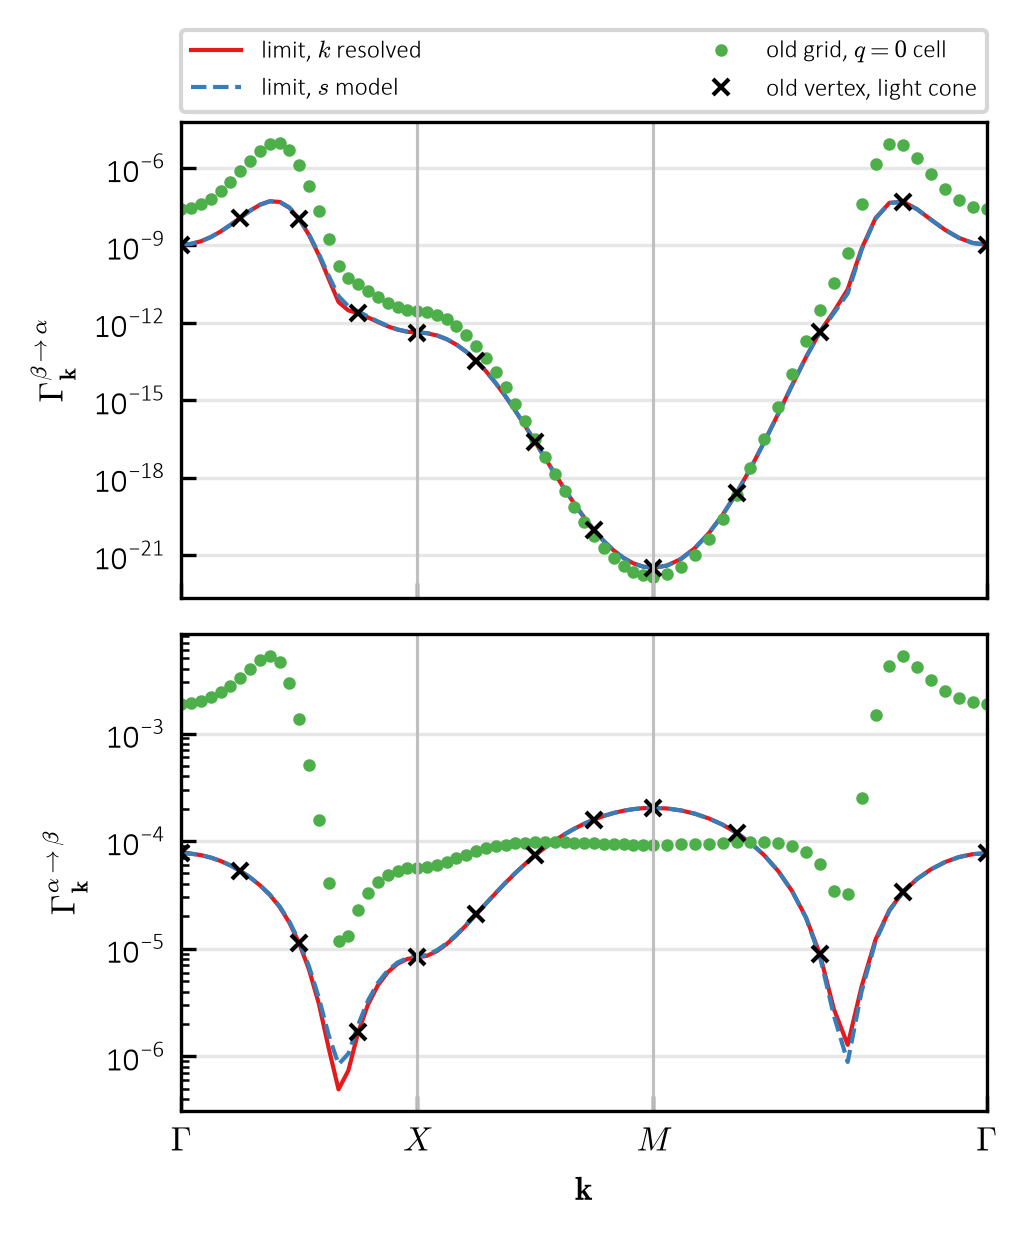

In [32]:
fig, axs = plt.subplots(2, 1, figsize=(W, 1.2 * W), sharex=True)
for j, (ax, lab) in enumerate(zip(axs, (r"\beta\to\alpha", r"\alpha\to\beta"))):
    ax.semilogy(xp, new_k[j], color=set1_list[0], lw=1.0, label="limit, $k$ resolved")
    ax.semilogy(xp, new_s[j], color=set1_list[1], lw=1.0, ls="--", label="limit, $s$ model")
    ax.semilogy(xp, old_grid[:, j], "o", ms=2, color=set1_list[2], label="old grid, $q=0$ cell")
    ax.semilogy(xp[sub], old_cone[:, j], "x", ms=4, color="k", label="old vertex, light cone")
    ax.set_ylabel(rf"$\Gamma^{{{lab}}}_{{\mathbf{{k}}}}$")
    path_axes(ax)
axs[0].legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
              borderaxespad=0, ncol=2, fontsize=6)
axs[1].set_xlabel(r"$\mathbf{k}$")
plt.tight_layout()
plt.show()

### 1b. Phonons: pair rates out of p0, alpha -> alpha

Old code (finite c_s, finite gam) against the same kernel with c_s -> 0 (`phonon_pair`,
cs = 0): they differ by O((omega_q / gam)^2). The gam -> 0 limit has no pointwise
pair rate (delta in energy), so it enters through the moments in 1c.

p0 / pi = [0. 0.]: max |old / (old kernel, this code) - 1| = 1.9e-13, max |limit / old - 1| = 3.5e-03


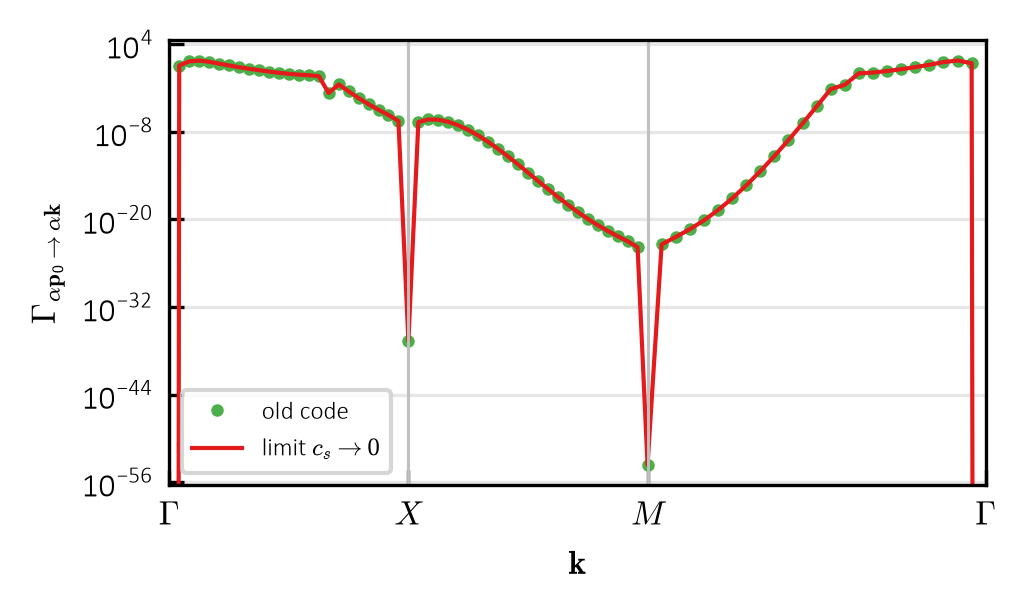

In [33]:
p0 = np.pi * np.asarray(cmp["p0"], float)
i_p0 = int(np.argmin(np.linalg.norm(np.mod(kk - p0 + np.pi, 2 * np.pi) - np.pi, axis=1)))
p0 = kk[i_p0]
r_old = np.asarray(pb.source_rates(st, [qn_old], 0, i_p0))[0, ip]
r_lim = lm.phonon_pair(p, dc, mc, qc, t2, kp, p0, cs=0.0)
r_cs = lm.phonon_pair(p, dc, mc, qc, t2, kp, p0, cs=cmp["cs"])
msk = r_old > 1e-14 * r_old.max()
print(f"p0 / pi = {p0 / np.pi}: max |old / (old kernel, this code) - 1| = {np.max(np.abs(r_cs[msk] / r_old[msk] - 1)):.1e}, "
      f"max |limit / old - 1| = {np.max(np.abs(r_lim[msk] / r_old[msk] - 1)):.1e}")

fig, ax = plt.subplots(figsize=(W, 0.6 * W))
ax.semilogy(xp, r_old, "o", ms=2, color=set1_list[2], label="old code")
ax.semilogy(xp, r_lim, color=set1_list[0], lw=1.0, label=r"limit $c_s\to0$")
ax.set_ylabel(r"$\Gamma_{\alpha\mathbf{p}_0\to\alpha\mathbf{k}}$")
ax.set_xlabel(r"$\mathbf{k}$")
path_axes(ax)
ax.legend(fontsize=6)
plt.tight_layout()
plt.show()

### 1c. Phonons: energy moments of the out rates, along the path (p0 = k)

M_j(p0) = sum_k w_k (E_k - E_p0)^j Gamma(p0 -> k), j = 1 (drift), 2 (diffusion).
- old code on the nk grid,
- limit kernel at finite gam (c_s -> 0) on a fine grid (nkf),
- gam -> 0 Fokker-Planck: M1 = -2 pi X, M2 = 4 pi T X, X = amp C~^2 [Phi + g |sin p0|^2] / |E'|,
- the same with |sin p0|^2 -> Phi / g (contour average, what the s model uses).

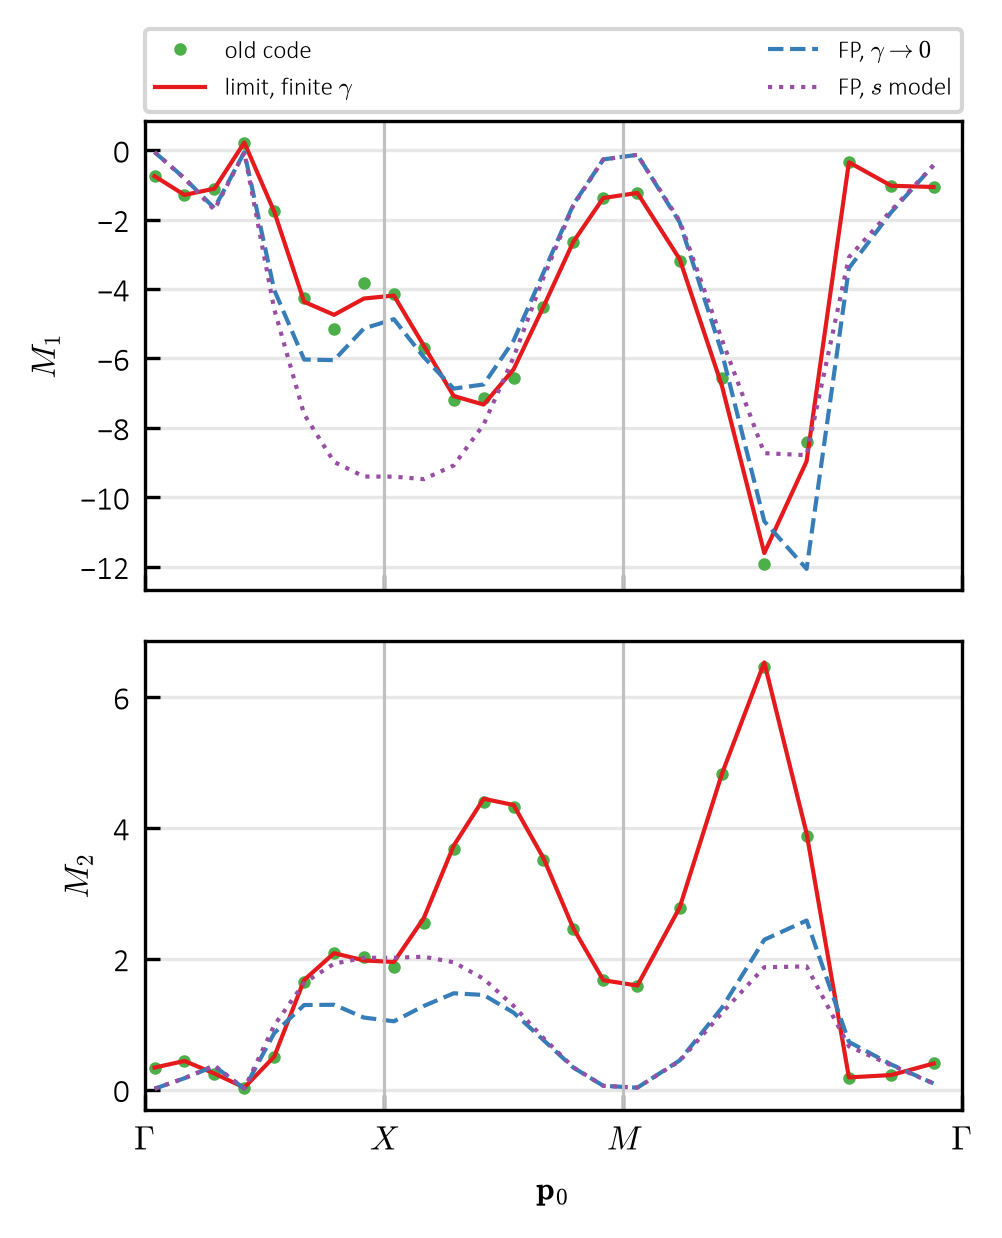

In [34]:
sub2 = np.arange(1, len(ip) - 1, max(1, len(ip) // 24))
ea = bk.ea
mo_old = np.array([[np.sum(np.asarray(pb.source_rates(st, [qn_old], 0, ip[j]))[0] * (ea - ea[ip[j]])**q) / N
                    for q in (1, 2)] for j in sub2])
mo_lim = np.array([lm.phonon_moments(p, dc, mc, qc, t2, kp[j], cmp["nkf"]) for j in sub2])
mo_fp = np.array([lm.fp_moments(p, dc, mc, qc, t2, kp[j]) for j in sub2])
mo_fps = []
for j in sub2:
    s0 = sk[j]
    hb = np.interp(s0, gr.s, gr.hb)
    a, c = lm.fp_moments(p, dc, mc, qc, t2, kp[j])
    scl = (lm.phi(s0) + lm.gs(s0) * hb) / (lm.phi(s0) + lm.gs(s0) * np.sum(np.sin(kp[j])**2))
    mo_fps.append((a * scl, c * scl))
mo_fps = np.array(mo_fps)

fig, axs = plt.subplots(2, 1, figsize=(W, 1.2 * W), sharex=True)
for q, ax in enumerate(axs):
    ax.plot(xp[sub2], mo_old[:, q], "o", ms=2, color=set1_list[2], label="old code")
    ax.plot(xp[sub2], mo_lim[:, q], color=set1_list[0], lw=1.0, label=r"limit, finite $\gamma$")
    ax.plot(xp[sub2], mo_fp[:, q], color=set1_list[1], lw=1.0, ls="--", label=r"FP, $\gamma\to0$")
    ax.plot(xp[sub2], mo_fps[:, q], color=set1_list[3], lw=1.0, ls=":", label=r"FP, $s$ model")
    ax.set_ylabel(rf"$M_{q + 1}$")
    path_axes(ax)
axs[0].legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
              borderaxespad=0, ncol=2, fontsize=6)
axs[1].set_xlabel(r"$\mathbf{p}_0$")
plt.tight_layout()
plt.show()

## 2. NESS at (T1, T2)

- quasi-Fermi: phonons much faster than photons, each band FD at T2 with its own mu,
- Newton on the 1D s model, started from the quasi-Fermi state,
- `solve_fixed` (mu Picard as ej.solve_fixed) from the thermal state at T2, with the band
  shift, and without it for comparison (it stalls: the interband mode is slow).

In [35]:
(mu_a, mu_b, dq, mq), sq = ls.solve_qf(gr, p, pc, t1, t2, dc, mc)
print(f"quasi-Fermi: d = {dq:.8f}, m = {mq:.8f}, mu_a - mu_b = {mu_a - mu_b:.6f}, "
      f"fold of the ordered branch at T1 / Tc = {sq.hist['fold'] and sq.hist['fold'] / tc}")
sn = ls.solve_newton(gr, p, pc, qc, t1, t2, sq.mu, dq, mq, tol=cfg["solve"]["newton_tol"],
                     nmax=cfg["solve"]["newton_nmax"])
b0 = lm.mf(p, gr.s, dc, mc)
_, _, muc2 = lm.thermal(gr, p, t2)
mu_start = np.r_[b0.ea - muc2, b0.eb - muc2] / t2
fx = dict(mix=tuple(cfg["solve"]["mix"]), tol=cfg["solve"]["tol"], nmax=cfg["solve"]["nmax"], chk=cfg["solve"]["chk"])
sf = ls.solve_fixed(gr, p, pc, qc, t1, t2, mu_start, dc, mc, shift=True, **fx)
s0 = ls.solve_fixed(gr, p, pc, qc, t1, t2, mu_start, dc, mc, shift=False, **{**fx, "nmax": min(fx["nmax"], 2000)})
for name, s in (("Newton", sn), ("fixed + shift", sf), ("fixed, no shift", s0)):
    print(f"{name:16s} d = {s.d:.8f}  m = {s.m:.8f}  err = {s.err:.1e}  it = {s.it}  "
          f"max |n - n_Newton| = {np.max(np.abs(s.n - sn.n)):.1e}")
te = ls.t_eff(gr, p, sn.d, tc)
print("T_eff / Tc =", None if te is None else te / tc, "(equilibrium state with the same gap)")

quasi-Fermi: d = 0.93402176, m = -0.69307710, mu_a - mu_b = 1.311611, fold of the ordered branch at T1 / Tc = None
Newton           d = 0.93402176  m = -0.69307710  err = 7.7e-11  it = 6  max |n - n_Newton| = 0.0e+00
fixed + shift    d = 0.93402179  m = -0.69307708  err = 1.0e-08  it = 300  max |n - n_Newton| = 2.1e-08
fixed, no shift  d = 0.99996922  m = -0.68434719  err = 1.3e+01  it = 2000  max |n - n_Newton| = 6.9e-02
T_eff / Tc = 0.5628397852366266 (equilibrium state with the same gap)


### 2a. Distributions against FD at T1, T2, T_eff and the per band quasi-Fermi FD

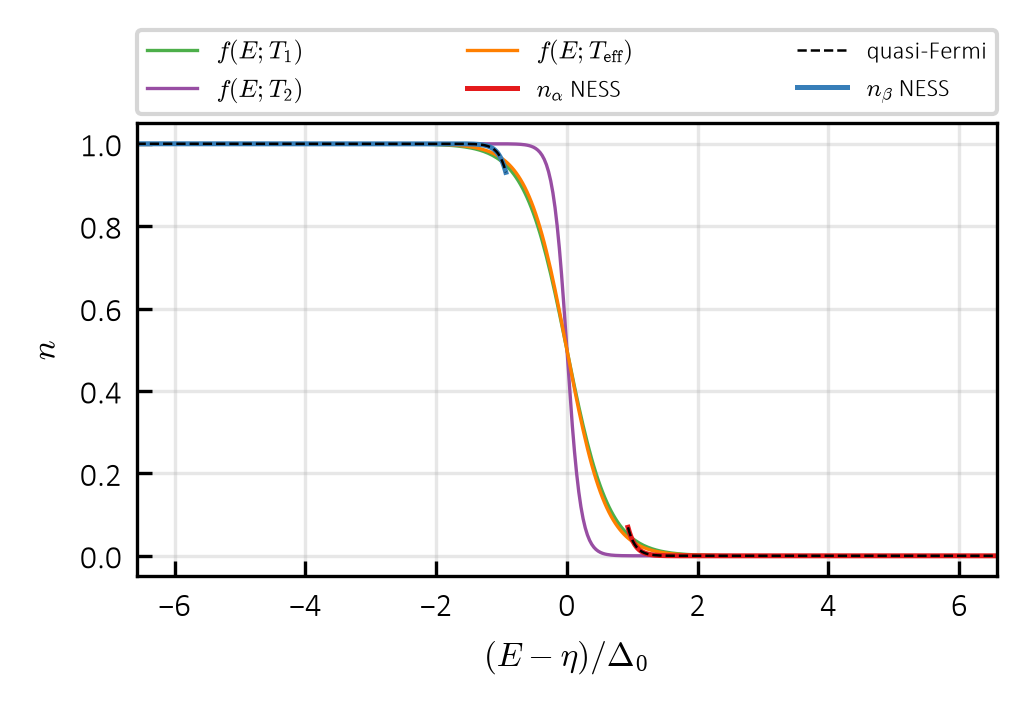

In [36]:
ns = len(gr.s)
bn = lm.mf(p, gr.s, sn.d, sn.m)
e = np.r_[bn.ea, bn.eb]
x = (e - eta0) / d00
ref = [(t1, "T_1"), (t2, "T_2")] + ([(te, r"T_{\rm eff}")] if te is not None else [])
mus = [lm.thermal(gr, p, t, fix_d=0.0 if t >= tc else None)[2] for t, _ in ref]
xs = np.linspace(x.min(), x.max(), 400)

fig, ax = plt.subplots(figsize=(W, 0.7 * W))
for i, ((t, lab), mu) in enumerate(zip(ref, mus)):
    ax.plot(xs, lm.fermi(xs * d00 + eta0 - mu, t), color=set1_list[i + 2], lw=0.8, label=rf"$f(E;{lab})$")
for g, (sl, lab) in enumerate(((slice(0, ns), r"\alpha"), (slice(ns, 2 * ns), r"\beta"))):
    o = np.argsort(x[sl])
    ax.plot(x[sl][o], sn.n[sl][o], color=set1_list[g], lw=1.2, label=rf"$n_{lab}$ NESS")
    ax.plot(x[sl][o], sq.n[sl][o], color="k", lw=0.6, ls="--", label="quasi-Fermi" if g == 0 else None)
ax.set_xlabel(r"$(E-\eta)/\Delta_0$")
ax.set_ylabel(r"$n$")
style(ax, xs)
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=3, fontsize=6)
plt.tight_layout()
plt.show()

### 2b. ln((1 - n) / n) = mu of every state: a straight line of slope 1 / T is FD at T

Bottom panel: deviation from the quasi-Fermi FD of each band, mu - (E - mu_gamma) / T2.

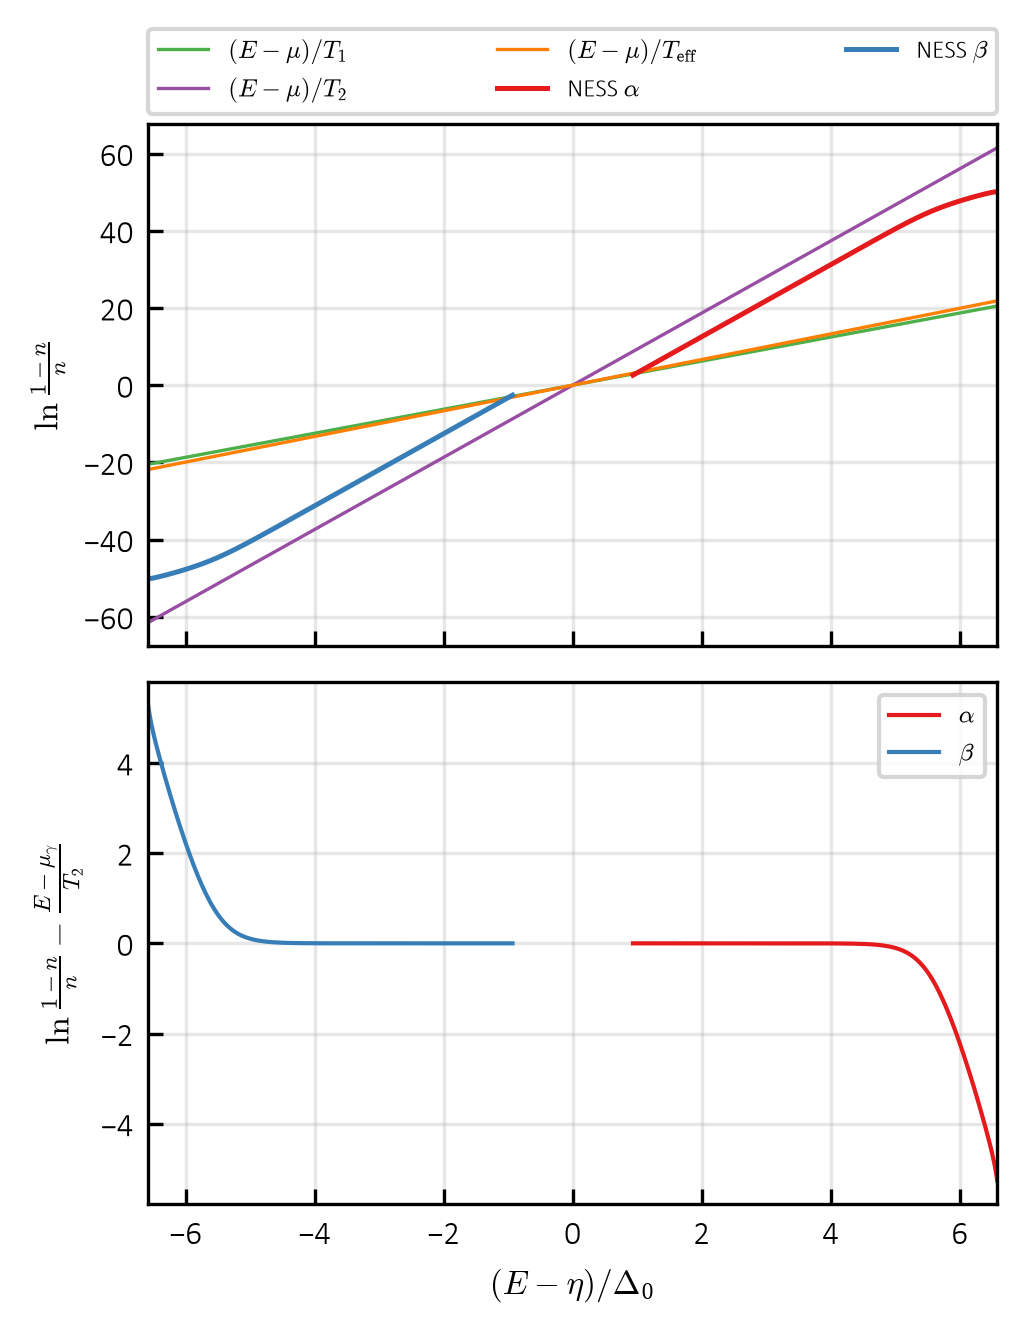

In [37]:
fig, axs = plt.subplots(2, 1, figsize=(W, 1.3 * W), sharex=True)
ax = axs[0]
for i, ((t, lab), mu) in enumerate(zip(ref, mus)):
    ax.plot(xs, (xs * d00 + eta0 - mu) / t, color=set1_list[i + 2], lw=0.8, label=rf"$(E-\mu)/{lab}$")
for g, (sl, lab) in enumerate(((slice(0, ns), r"\alpha"), (slice(ns, 2 * ns), r"\beta"))):
    o = np.argsort(x[sl])
    ax.plot(x[sl][o], sn.mu[sl][o], color=set1_list[g], lw=1.2, label=rf"NESS ${lab}$")
ax.set_ylabel(r"$\ln\frac{1-n}{n}$")
style(ax, xs)
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", borderaxespad=0, ncol=3, fontsize=6)
ax = axs[1]
for g, (sl, lab, mg) in enumerate(((slice(0, ns), r"\alpha", mu_a), (slice(ns, 2 * ns), r"\beta", mu_b))):
    o = np.argsort(x[sl])
    ax.plot(x[sl][o], sn.mu[sl][o] - (e[sl][o] - mg) / t2, color=set1_list[g], lw=1.0, label=rf"${lab}$")
ax.set_xlabel(r"$(E-\eta)/\Delta_0$")
ax.set_ylabel(r"$\ln\frac{1-n}{n}-\frac{E-\mu_\gamma}{T_2}$")
style(ax, xs)
ax.legend(fontsize=6)
plt.tight_layout()
plt.show()